# 13 · CV cluster states at scale, and a first digital twin

Measurement-based CV quantum computing runs on **cluster states**: squeezed modes entangled by
controlled-phase gates $CZ=e^{i x_jx_k}$. Time-multiplexed experiments generate one-dimensional
clusters of thousands of temporal modes (Menicucci, *PRA* **83**, 062314, 2011; Yokoyama *et al.*,
*Nature Photonics* **7**, 982, 2013; Asavanant *et al.*, *Science* **366**, 373, 2019). This is the
regime of D12: every element is Gaussian, so the exact backend handles the whole machine, and the
tensor network is kept for the few non-Gaussian modes injected into it.

For a 1D cluster built from $p$-squeezed modes ($\mathrm{Var}\,p=e^{-2r}/2$), the **nullifiers**
$\delta_k=p_k-x_{k-1}-x_{k+1}$ have variance $e^{-2r}/2$; with loss $\eta$ on every mode afterwards,

$$
\mathrm{Var}\,\delta_k = \eta\,\frac{e^{-2r}}{2} + (1-\eta)\,\frac{3}{2}\qquad(\text{interior modes; } \tfrac{2}{2}\text{ at the two ends}).
$$

1. Build the cluster with the Gaussian backend and check the formula (and a 2-mode case against the
   dense oracle).
2. Scale to 800 modes.
3. A digital-twin noise budget: source squeezing, element loss, detector efficiency and phase noise.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tutorial_utils as tu
from tutorial_utils import cd, dr

print(tu.cv_banner())
if tu.HAVE_GAUSSIAN:
    from qttlind.gaussian import GaussianState, ops
checks = {}


def cz_chain_symplectic(M, g=1.0):
    # all CZ gates of a chain commute: one symplectic matrix, p_k -> p_k + g (x_{k-1} + x_{k+1})
    S = np.eye(2 * M)
    for k in range(M - 1):
        S[M + k + 1, k] += g
        S[M + k, k + 1] += g
    return S


def nullifier_vectors(M, g=1.0):
    vs = []
    for k in range(M):
        v = np.zeros(2 * M); v[M + k] = 1.0
        if k > 0: v[k - 1] = -g
        if k < M - 1: v[k + 1] = -g
        vs.append(v)
    return np.array(vs)


def predicted(M, r, eta):
    nb = np.array([1 + (k > 0) + (k < M - 1) for k in range(M)])
    return eta * np.exp(-2 * r) / 2 + (1 - eta) * nb / 2

qttlind 2.0.0 -- gaussian backend: yes; quantics CV: yes; circuits: yes.


## 1. The cluster and its nullifiers

Two-mode check against the dense oracle: $CZ=\exp(ix_1x_2)$ by `expm` in a truncated Fock space.

In [2]:
# dense two-mode cluster: p-squeezed inputs (S(r, pi) squeezes p)
r2, N = 0.3, 40
x, p = cd.quadratures(N)
X1, X2 = np.kron(x, np.eye(N)), np.kron(np.eye(N), x)
from scipy.linalg import expm
sq = cd.squeezed_vacuum_amplitudes(N, r2, np.pi)
psi = expm(1j * X1 @ X2) @ np.kron(sq, sq)
mean, V2 = cd.moments(np.outer(psi, psi.conj()), [N, N])
dense_null = [nv @ V2 @ nv for nv in nullifier_vectors(2)]
checks["2-mode cluster: dense oracle vs formula"] = (np.abs(np.array(dense_null) - predicted(2, r2, 1.0)).max(), 1e-6)

if tu.HAVE_GAUSSIAN:
    M, r = 12, 1.0
    s = GaussianState.product(*[GaussianState.squeezed_vacuum(r, np.pi)] * M)
    s = ops.apply_symplectic(s, cz_chain_symplectic(M))
    for eta in (1.0, 0.8):
        lossy = s
        for k in range(M):
            lossy = ops.loss(lossy, eta, mode=k)
        var = np.array([nv @ lossy.cov @ nv for nv in nullifier_vectors(M)])
        checks[f"{M}-mode cluster nullifiers, eta = {eta}"] = (np.abs(var - predicted(M, r, eta)).max(), 1e-12)
    s2 = ops.apply_symplectic(GaussianState.product(*[GaussianState.squeezed_vacuum(r2, np.pi)] * 2), cz_chain_symplectic(2))
    checks["2-mode cluster: Gaussian backend vs dense oracle"] = (np.abs(s2.cov - V2).max(), 1e-6)

## 2. At the scale of a time-multiplexed machine

Building the state and applying loss costs $O(M^3)$ dense linear algebra (a production code would
exploit the banded structure). A few hundred modes take seconds.

seconds: [0.02, 0.11, 0.88, 6.35]


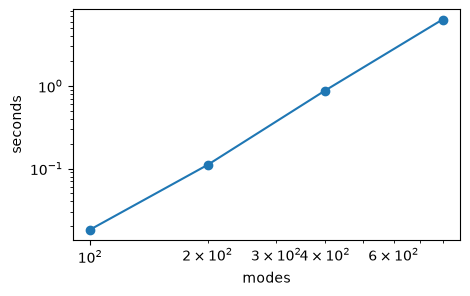

In [3]:
if tu.HAVE_GAUSSIAN:
    sizes, secs = [100, 200, 400, 800], []
    for M in sizes:
        t0 = time.perf_counter()
        s = GaussianState.product(*[GaussianState.squeezed_vacuum(1.0, np.pi)] * M)
        s = ops.apply_symplectic(s, cz_chain_symplectic(M))
        X = np.sqrt(0.9) * np.eye(2 * M); Y = 0.1 / 2 * np.eye(2 * M)
        s = ops.apply_channel(s, X, Y)             # 10 % loss on every mode at once
        var = np.einsum("ki,ij,kj->k", nullifier_vectors(M), s.cov, nullifier_vectors(M))
        secs.append(time.perf_counter() - t0)
        checks[f"{M}-mode cluster nullifiers"] = (np.abs(var - predicted(M, 1.0, 0.9)).max(), 1e-10)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.loglog(sizes, secs, "o-"); ax.set_xlabel("modes"); ax.set_ylabel("seconds")
    tu.savefig(fig, "13_cluster_scaling.png")
    print("seconds:", [round(t, 2) for t in secs])
else:
    print("qttlind.gaussian is not available: large clusters skipped.")

## 3. A digital-twin noise budget

A hardware model lists the imperfections of a specific device; compiled into the circuit, it
predicts what the device will measure. Here, by hand (`qttlind.circuits.HardwareModel` automates it, below):

* source squeezing (dB) — sets $r$;
* element loss $\eta_e$ (propagation, delay lines, couplers) and detector efficiency $\eta_d$: both are
  loss, $\eta=\eta_e\eta_d$;
* phase noise of the local oscillator, $\theta\sim\mathcal N(0,\sigma^2)$ per mode: a *mixture* of rotated
  Gaussian states. For zero-mean states its covariance is the average of the rotated covariances —
  estimated here by Monte Carlo.

The nullifier variance is shown in dB relative to the vacuum value ($3/2$ for interior modes).

Phase noise rotates the anti-squeezed quadrature (variance e^{+2r}/2) into the nullifiers: its cost grows with the squeezing.


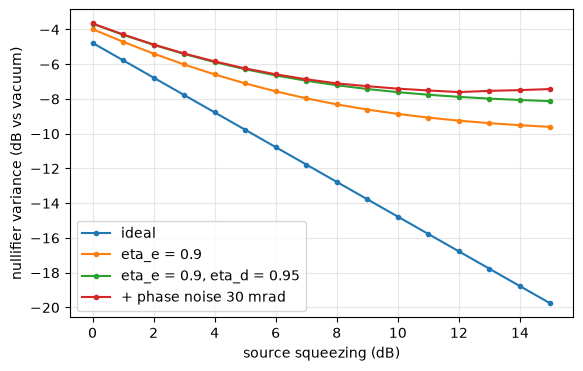

In [4]:
dbs = np.linspace(0, 15, 16)
budgets = {"ideal": (1.0, 1.0, 0.0), "eta_e = 0.9": (0.9, 1.0, 0.0),
           "eta_e = 0.9, eta_d = 0.95": (0.9, 0.95, 0.0), "+ phase noise 30 mrad": (0.9, 0.95, 0.03)}
rng = np.random.default_rng(3)
fig, ax = plt.subplots(figsize=(6.5, 4))
for label, (ee, ed, sig) in budgets.items():
    curve = []
    for db in dbs:
        r = db / (20 * np.log10(np.e))
        eta = ee * ed
        if not tu.HAVE_GAUSSIAN:
            curve.append(predicted(3, r, eta)[1]); continue
        M = 3
        s = ops.apply_symplectic(GaussianState.product(*[GaussianState.squeezed_vacuum(r, np.pi)] * M), cz_chain_symplectic(M))
        for k in range(M):
            s = ops.loss(s, eta, mode=k)
        if sig > 0:
            Vs = []
            for _ in range(200):
                t = s
                for k in range(M):
                    t = ops.rotate(t, rng.normal(0, sig), mode=k)
                Vs.append(t.cov)
            V = np.mean(Vs, axis=0)
        else:
            V = s.cov
        curve.append(nullifier_vectors(M)[1] @ V @ nullifier_vectors(M)[1])
    ax.plot(dbs, 10 * np.log10(np.array(curve) / 1.5), "o-", ms=3, label=label)
ax.set_xlabel("source squeezing (dB)"); ax.set_ylabel("nullifier variance (dB vs vacuum)"); ax.legend()
ax.grid(alpha=0.3); tu.savefig(fig, "13_noise_budget.png")
print("Phase noise rotates the anti-squeezed quadrature (variance e^{+2r}/2) into the nullifiers: its cost grows with the squeezing.")

### With the `circuits` layer

Once `"cv_circuits"` is registered, the same budget is a `HardwareModel` compiled into a
`Circuit` and run by any executor; the hybrid executor also accepts non-Gaussian elements
(a GKP or cubic-phase injection into one mode) and moves only that part to the comb.

In [5]:
if tu.HAVE_CIRCUITS:
    from qttlind.circuits import Circuit, GaussianExecutor, HardwareModel
    c = Circuit(1).squeeze(0, 1.0)
    model = HardwareModel(element_loss={"squeeze": 0.9})
    res = GaussianExecutor().run(model.compile(c))
    ref = ops.loss(GaussianState.squeezed_vacuum(1.0), 0.9)
    checks["HardwareModel.compile: element loss"] = (np.abs(res.state.cov - ref.cov).max(), 1e-12)
else:
    print("qttlind.circuits is not available: the budget above was compiled by hand.")

## Acceptance table

In [6]:
for name, (dev, tol) in checks.items():
    print(f"{'ok ' if dev <= tol else 'FAIL'} {name:<52s} deviation {dev:9.2e}  (tolerance {tol:.0e})")
assert all(dev <= tol for dev, tol in checks.values()), "a benchmark is outside its tolerance"

ok  2-mode cluster: dense oracle vs formula              deviation  5.83e-15  (tolerance 1e-06)
ok  12-mode cluster nullifiers, eta = 1.0                deviation  1.67e-16  (tolerance 1e-12)
ok  12-mode cluster nullifiers, eta = 0.8                deviation  2.78e-16  (tolerance 1e-12)
ok  2-mode cluster: Gaussian backend vs dense oracle     deviation  4.11e-15  (tolerance 1e-06)
ok  100-mode cluster nullifiers                          deviation  5.55e-16  (tolerance 1e-10)
ok  200-mode cluster nullifiers                          deviation  5.55e-16  (tolerance 1e-10)
ok  400-mode cluster nullifiers                          deviation  5.55e-16  (tolerance 1e-10)
ok  800-mode cluster nullifiers                          deviation  5.55e-16  (tolerance 1e-10)
ok  HardwareModel.compile: element loss                  deviation  4.44e-16  (tolerance 1e-12)
